In [32]:
from sklearn.datasets import load_diabetes

data = load_diabetes(as_frame=True)

df = data.frame

In [33]:
#1- الcoefficiant لما يكون كبير معناتو انو النموذج  عم يعطي اهمية كبيرة بمعامل معين و تفاصيل صغيرة بمعامل معين و بترك المعاملات و التفاصيل التانية بتاثير قليل جدا
#2- الRidge و اللي فهمتو انو بحول يخلي كل الالاشياء تعطي تاثير على النتيجة و هاي بخلي النموذج عام و ممكن يكون مطلوب ببعض التطيقات على حسب انت ايش يدك تصمم
#2- الوLasso ممكن يعطي بعض المعاملات قيمة صفر يعني انو المعامل هاد ما الو دخل بالنتيجة فبتم اهمالو و بسير النموذج متخصص اكتر كمان يستعمل على حسب ايش بدي اصمم
#3- الalpha لو كان عالي اتوقع انو النموذج رح ايسط عشان التغيرات اللي تعتبر صغيرة ممكن باخد عليها عقوبة فبضل يحاول يصير ابسط 

In [34]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [35]:
x_all = df.drop('target', axis=1)
y_all = df['target']
x_train, x_test, y_train, y_test = train_test_split(x_all, y_all, test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(x_train, y_train)
linear_pred = linear_model.predict(x_test)

ridge_model = Ridge(alpha=1)
ridge_model.fit(x_train, y_train)
ridge_pred = ridge_model.predict(x_test)

In [36]:
linear_mae_s = mean_absolute_error(y_test, linear_pred)
linear_mse_s = mean_squared_error(y_test ,linear_pred)
linear_r2_s = r2_score(y_test ,linear_pred)
linear_rmse_s= np.sqrt(linear_mse_s)

ridge_mae_s = mean_absolute_error(y_test, ridge_pred)
ridge_mse_s = mean_squared_error(y_test, ridge_pred)
ridge_r2_s = r2_score(y_test, ridge_pred)
ridge_rmse_s = np.sqrt(ridge_mse_s)

print(f"linear_mae_s:{linear_mae_s}, linear_mse_s:{linear_mse_s}, linear_r2_s:{linear_r2_s}, linear_rmse_s:{linear_rmse_s}")
print(f"ridge_mae_s:{ridge_mae_s}, ridge_mse_s:{ridge_mse_s}, ridge_r2_s:{ridge_r2_s}, ridge_rmse_s:{ridge_rmse_s}")


linear_mae_s:42.79409467959994, linear_mse_s:2900.1936284934814, linear_r2_s:0.4526027629719195, linear_rmse_s:53.85344583676593
ridge_mae_s:46.13885766697452, ridge_mse_s:3077.4159388272296, ridge_r2_s:0.41915292635986556, ridge_rmse_s:55.47446204180109


In [37]:
print(f"linear_model_coef {linear_model.coef_}")
print(f"ridge_model_coef{ridge_model.coef_}")

linear_model_coef [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
ridge_model_coef[  45.36737726  -76.66608563  291.33883165  198.99581745   -0.53030959
  -28.57704987 -144.51190505  119.26006559  230.22160832  112.14983004]


In [38]:
alpha_to_test = [0.1, 1.0, 10.0]
for i in alpha_to_test:
    test_ridge = Ridge(alpha=i)
    test_ridge.fit(x_train,y_train)
    test_ridge_pred = test_ridge.predict(x_test)
    r2 = r2_score(y_test, test_ridge_pred)
    print(f"ridge with alpha: {i} -> R² = {r2:.4f}")

ridge with alpha: 0.1 -> R² = 0.4609
ridge with alpha: 1.0 -> R² = 0.4192
ridge with alpha: 10.0 -> R² = 0.1612


In [39]:
from sklearn.linear_model import Lasso

Lasso_model = Lasso(alpha=1)
Lasso_model.fit(x_train, y_train)
Lasso_model_pred = Lasso_model.predict(x_test)
l_r2 = r2_score(y_test, Lasso_model_pred)

print(f"Lasso R² (alpha=1): {l_r2:.4f}")
print("Lasso Coefficients:\n", Lasso_model.coef_)

Lasso R² (alpha=1): 0.3576
Lasso Coefficients:
 [  0.          -0.         413.43184792  34.83051518   0.
   0.          -0.           0.         258.15289363   0.        ]


In [40]:
Lasso_model_2 = Lasso(alpha=5)
Lasso_model_2.fit(x_train, y_train)
Lasso_model_pred_2 = Lasso_model_2.predict(x_test)
l_r2_2 = r2_score(y_test, Lasso_model_pred_2)

print(f"Lasso R² (alpha=1): {l_r2_2:.4f}")
print("Lasso Coefficients:\n", Lasso_model_2.coef_)

Lasso R² (alpha=1): -0.0120
Lasso Coefficients:
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [41]:
import pandas as pd

# تجميع المعاملات بجدول للمقارنة
coef_df = pd.DataFrame({
    'Features': x_train.columns,
    'Linear': linear_model.coef_,
    'Ridge (a=1)': ridge_model.coef_,
    'Lasso (a=1)': Lasso_model.coef_
})

print(coef_df)

  Features      Linear  Ridge (a=1)  Lasso (a=1)
0      age   37.904021    45.367377     0.000000
1      sex -241.964362   -76.666086    -0.000000
2      bmi  542.428759   291.338832   413.431848
3       bp  347.703844   198.995817    34.830515
4       s1 -931.488846    -0.530310     0.000000
5       s2  518.062277   -28.577050     0.000000
6       s3  163.419983  -144.511905    -0.000000
7       s4  275.317902   119.260066     0.000000
8       s5  736.198859   230.221608   258.152894
9       s6   48.670657   112.149830     0.000000


In [42]:

alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
train_mse = []
test_mse = []

for i in alphas:
    my_model = Ridge(alpha= i)
    my_model.fit(x_train, y_train)

    my_model_train_pred = my_model.predict(x_train)
    my_model_test_pred = my_model.predict(x_test)

    train_mse.append(mean_squared_error(y_train, my_model_train_pred))
    test_mse.append(mean_squared_error(y_test, my_model_test_pred))

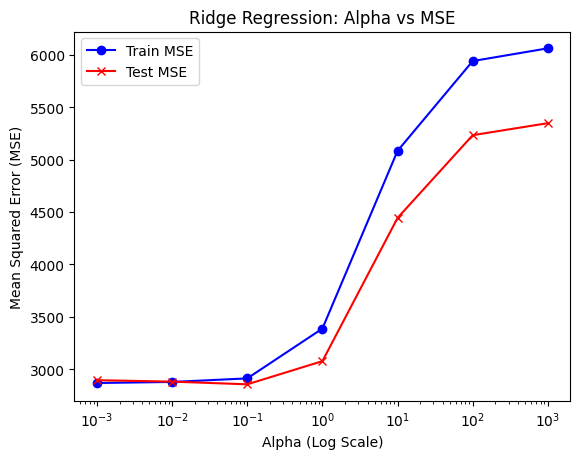

In [ ]:
import matplotlib.pyplot as plt

plt.plot(alphas, train_mse, label='Train MSE', marker='o', color='blue')
plt.plot(alphas, test_mse, label='Test MSE', marker='x', color='red')

plt.xscale('log') 
plt.xlabel('Alpha (Log Scale)')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Ridge Regression: Alpha vs MSE')
plt.legend()
plt.show()

# بحس انو المكان اللي عند 10قوة سالب 1

#هاد المكان التوقعات قريبة من الاختبار

#بس اللي قبلها نفي الاشي هاد بدل انو باصم overfiting

#و اللي بعدها او الاكبر منها بلشو يبعدو كتير عشان العقاب صار اقسى فصار underfiting

#و ممكن نعتبر النقطة اللي جنبها 10 قوة 0 تكون منيحة ما بعرف هاد اللي انا شايفو

In [59]:
score_df = pd.DataFrame({'model':['linear_model', 'ridge_model', 'Lasso_model', 'Polynomial_model' ],
                         'mse':[linear_mse_s, ridge_mse_s, mean_squared_error(y_test, Lasso_model_pred), '4085.025480'], 
                         'mae':[linear_mae_s, ridge_mae_s, mean_absolute_error(y_test, Lasso_model_pred), '52.383911'],
                         'rmse':[linear_rmse_s, ridge_rmse_s, np.sqrt(mean_squared_error(y_test, Lasso_model_pred)), '63.914204'],
                         'r2_score':[linear_r2_s, ridge_r2_s, l_r2_2, '0.228971']})

score_df.set_index('model', inplace=True)
print(score_df)

                          mse        mae       rmse  r2_score
model                                                        
linear_model      2900.193628  42.794095  53.853446  0.452603
ridge_model       3077.415939  46.138858  55.474462  0.419153
Lasso_model       3403.575722  49.730328  58.340172 -0.011963
Polynomial_model  4085.025480  52.383911  63.914204  0.228971


### الجزء 5 — المقارنة الشاملة النهائية

| النموذج | MAE | MSE | RMSE | R² | ملاحظات |
|---|---|---|---|---|---|
| Linear Regression (كل المتغيرات) | 42.79 | 2900.19 | 53.85 | 0.452 | الأداء الأفضل، توازن واضح بدون Overfitting. |
| Polynomial Regression (متغير bmi بس، درجة 2) | 52.38 | 4085.02 | 63.91 | 0.228 | أداء ضعيف، العلاقة لا تتطلب تعقيد النموذج لدرجة ثانية. |
| Ridge (alpha=0.1) | 46.13 | 3077.41 | 55.47 | 0.419 | العقوبة قللت حجم المعاملات لكنها خفضت الدقة قليلاً. |
| Lasso (alpha=1.0) | 49.73 | 3403.57 | 58.34 | -0.011 | عقوبة قاسية جداً أدت لتصفير المعاملات وتدمير التوقع. |

**1. النموذج الذي حقق أفضل أداء:**
نموذج الانحدار الخطي العادي (Linear Regression).

**2. مبررات اختيار النموذج:**
بناءً على الأرقام، تفوق نموذج الانحدار الخطي العادي بوضوح محققاً أعلى معامل ارتباط R² (0.452) وأقل متوسط خطأ تربيعي MSE (2900). نموذج البولينوميال سجل أداءً أضعف بكثير (R² = 0.228)، مما يؤكد أن طبيعة العلاقة تميل للخطية ولا تستدعي تعقيد المنحنيات. أما بخصوص نماذج الـ Regularization، فقد أدى استخدام Ridge و Lasso إلى تراجع ملحوظ في الأداء بدل تحسينه. هذا يثبت عملياً أن النموذج الخطي الأصلي لم يكن يعاني من Overfitting من الأساس، وبالتالي لم تكن هناك حاجة لفرض عقوبات. الأسوأ كان نموذج Lasso الذي فرض عقوبة قاسية لدرجة تصفير المعاملات، مما أدى لانهيار التوقع وتسجيل R² بالسالب.

**3. خطوات إضافية للتحسين مستقبلاً:**
لو توفر وقت إضافي، كنت سأقوم بتطبيق Data Scaling (مثل StandardScaler) لأن نماذج Ridge و Lasso حساسة جداً لحجم المتغيرات، وتوحيد المقياس قد يغير من استجابتها للعقوبة. كما كنت سأجرب استخدام خوارزمية Elastic Net التي تدمج بين خصائص Ridge و Lasso معاً، بالإضافة لتجربة Feature Engineering لإنشاء متغيرات مركبة جديدة قد تكشف أنماطاً مخفية في البيانات.